# Statistical Analysis of Videos DATASET


In [18]:
#libraries
import pandas as pd
import json 
import numpy as np
import statsmodels.api as sm 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_json('tiktok_booktok_2025_data.jsonl', lines=True)
print(df.head())

                    id  like_count region_code  \
0  7455100765804285206         331          PL   
1  7455099290818563350          12          PL   
2  7455097266605427990         269          PL   
3  7455096763297303830        1878          PL   
4  7455095111274237206          63          PL   

                                   video_description  favorites_count  \
0  #FLAWLESS | powtarzam pożar pożar || #booktok ...               55   
1  люблю цю історію😭 я ще не дочитала, але ця кни...                0   
2  Kochajmy Alexa #viral #booktok #ksiazkara #ann...               43   
3  Najlepszy i najgroźniejszy 🤫 #seriahellish #he...              464   
4  Boże jak mi się podoba ten tik tok😍 nie widzia...               11   

                                       hashtag_names  effect_ids  \
0  [flawless, beya, allofyourflaws, booktok, book...          []   
1  [reading, книги, читання, booktok, ninthhouse,...          []   
2         [dc, viral, booktok, annahuang, ksiazkara]  [1

In [4]:
print(df.columns)

Index(['id', 'like_count', 'region_code', 'video_description',
       'favorites_count', 'hashtag_names', 'effect_ids', 'is_stem_verified',
       'playlist_id', 'username', 'video_duration', 'video_label',
       'comment_count', 'create_time', 'music_id', 'view_count',
       'video_mention_list', 'voice_to_text', 'hashtag_info_list',
       'share_count', 'sticker_info_list', 'effect_info_list', 'video_tag'],
      dtype='object')


In [5]:
print(df.shape)

(51270, 23)


In [6]:
numeric_cols = ['view_count', 'like_count', 'comment_count', 'share_count', 'favorites_count', 'video_duration']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce').fillna(0)
print(df[numeric_cols].describe())

         view_count     like_count  comment_count   share_count  \
count  5.127000e+04   51270.000000    51270.00000  51270.000000   
mean   3.480900e+03     325.354496        6.66616     22.121631   
std    2.657741e+04    2924.540541       44.54357    363.742248   
min    0.000000e+00       0.000000        0.00000      0.000000   
25%    4.500000e+02      27.000000        0.00000      0.000000   
50%    8.000000e+02      57.000000        2.00000      1.000000   
75%    1.431000e+03     127.000000        5.00000      5.000000   
max    2.704824e+06  271394.000000     3272.00000  53779.000000   

       favorites_count  video_duration  
count     51270.000000    51270.000000  
mean         49.681471       22.735713  
std         386.529426       58.565714  
min           0.000000        0.000000  
25%           2.000000        0.000000  
50%           6.000000       11.000000  
75%          16.000000       17.000000  
max       30888.000000     2319.000000  


# 1. Data Preparation and Analysis of Means
## Creating Relative Indicators (Proxies for Trust and Engagement)


In [7]:
df['like_per_view'] = df['like_count'] / np.maximum(df['view_count'], 1)
df['favorite_per_view'] = df['favorites_count'] / np.maximum(df['view_count'], 1)
df['share_per_view'] = df['share_count'] / np.maximum(df['view_count'], 1)
df['comment_per_view'] = df['comment_count'] / np.maximum(df['view_count'], 1)
df['favorite_to_like_ratio'] = df['favorites_count'] / np.maximum(df['like_count'], 1)  # Wskaźnik głębokiego intencjonalnego wyboru


## Analysis of Means and Descriptive Statistics


In [8]:
stats_summary = df[numeric_cols + ['like_per_view', 'favorite_per_view', 'favorite_to_like_ratio']].describe().T
stats_summary['median'] = df[numeric_cols + ['like_per_view', 'favorite_per_view', 'favorite_to_like_ratio']].median()
stats_summary = stats_summary[['count', 'mean', 'std', 'median', 'min', 'max']]



In [9]:
print(stats_summary.round(4))

                          count       mean         std    median  min  \
view_count              51270.0  3480.8996  26577.4134  800.0000  0.0   
like_count              51270.0   325.3545   2924.5405   57.0000  0.0   
comment_count           51270.0     6.6662     44.5436    2.0000  0.0   
share_count             51270.0    22.1216    363.7422    1.0000  0.0   
favorites_count         51270.0    49.6815    386.5294    6.0000  0.0   
video_duration          51270.0    22.7357     58.5657   11.0000  0.0   
like_per_view           51270.0     0.0845      0.0534    0.0774  0.0   
favorite_per_view       51270.0     0.0102      0.0137    0.0079  0.0   
favorite_to_like_ratio  51270.0     0.1311      0.1221    0.1053  0.0   

                              max  
view_count              2704824.0  
like_count               271394.0  
comment_count              3272.0  
share_count               53779.0  
favorites_count           30888.0  
video_duration             2319.0  
like_per_view    

# 2. Rankings: Top Creators and Most Popular Videos

In [10]:
# Top Creators 
top_creators = df.groupby('username').agg(
    total_videos=('id', 'count'),
    total_views=('view_count', 'sum'),
    avg_views=('view_count', 'mean'),
    avg_favorites=('favorites_count', 'mean'),
    avg_fav_to_like=('favorite_to_like_ratio', 'mean')
).sort_values(by='total_views', ascending=False).head(10)
print("\nTOP 10 CREATORS BY TOTAL VIEWS")
print(top_creators)



TOP 10 CREATORS BY TOTAL VIEWS
                 total_videos  total_views     avg_views  avg_favorites  \
username                                                                  
turkishdizifans            72      7618575  1.058135e+05     871.638889   
storytel.pl                 6      2779416  4.632360e+05     177.000000   
callsign_alibi             10      1884652  1.884652e+05    3425.500000   
user19292920187             1      1867881  1.867881e+06    7264.000000   
mrpkzx                     17      1854455  1.090856e+05    2973.529412   
saraasjournal              40      1648180  4.120450e+04     322.600000   
fankawarnera               87      1531346  1.760168e+04     379.643678   
aagbyzuza                  73      1457008  1.995901e+04     196.712329   
o.t.cloud                   6      1317599  2.195998e+05    5782.833333   
readwithmily               81      1215529  1.500653e+04     196.098765   

                 avg_fav_to_like  
username                        

In [11]:
#Most Popular Videos
most_popular_videos = df[['id', 'username', 'view_count', 'favorites_count', 'favorite_to_like_ratio', 'video_description']].sort_values(
    by='favorite_to_like_ratio', ascending=False
).head(10)
print("\nTOP 10 VIDEOS BY FAVORITE TO LIKE RATIO")
print(most_popular_videos)


TOP 10 VIDEOS BY FAVORITE TO LIKE RATIO
                        id                username  view_count  \
29914  7539282772666371350         jasmina.autorka         810   
50670  7589032602695142678       thelordofthe7sins          48   
19708  7512230162797268246               mo0n.veil         511   
19412  7511065164817468694       pagesofinspiratio         804   
27653  7533340092098710806           rogomir.pisze          86   
11670  7489548153448959234           adelazalewska         289   
40258  7564491689742716182  twisted.reads.official       20947   
43509  7572676447446306070  twisted.reads.official       21732   
39782  7563371122184441110  twisted.reads.official       23529   
38008  7559301278304652566  twisted.reads.official       52385   

       favorites_count  favorite_to_like_ratio  \
29914                3                3.000000   
50670                2                2.000000   
19708                2                2.000000   
19412                2          

# 3. Korelacja i Model Regresji

In [12]:
# Spearman's correlation matrix 
correlation_matrix = df[['view_count', 'like_count', 'favorites_count', 'share_count', 'comment_count', 'video_duration']].corr(method='spearman')


In [13]:
print("\SPEARMAN'S CORRELATION MATRIX")
print(correlation_matrix.round(3))

\SPEARMAN'S CORRELATION MATRIX
                 view_count  like_count  favorites_count  share_count  \
view_count            1.000       0.811            0.750        0.584   
like_count            0.811       1.000            0.833        0.675   
favorites_count       0.750       0.833            1.000        0.633   
share_count           0.584       0.675            0.633        1.000   
comment_count         0.406       0.470            0.409        0.407   
video_duration       -0.073      -0.008           -0.063       -0.002   

                 comment_count  video_duration  
view_count               0.406          -0.073  
like_count               0.470          -0.008  
favorites_count          0.409          -0.063  
share_count              0.407          -0.002  
comment_count            1.000           0.100  
video_duration           0.100           1.000  


<>:1: SyntaxWarning: invalid escape sequence '\S'
<>:1: SyntaxWarning: invalid escape sequence '\S'
C:\Users\geraa\AppData\Local\Temp\ipykernel_12680\2359465954.py:1: SyntaxWarning: invalid escape sequence '\S'
  print("\SPEARMAN'S CORRELATION MATRIX")


In [14]:
# OLS Multiple Regression Model: What influences the number of favorites (favorites_count)?
# Logarithmic transformation: log1p(x) = log(1 + x)
df['log_views'] = np.log1p(df['view_count'])
df['log_favorites'] = np.log1p(df['favorites_count'])
df['log_comments'] = np.log1p(df['comment_count'])
df['log_shares'] = np.log1p(df['share_count'])
df['log_duration'] = np.log1p(df['video_duration'])

In [15]:
X = df[['log_views', 'log_comments', 'log_shares', 'log_duration']]
X = sm.add_constant(X)
y = df['log_favorites']

model = sm.OLS(y, X).fit()

In [17]:


print("\n WYNIKI MODELU REGRESJI LINIOWEJ (OLS)")
print(model.summary())


 WYNIKI MODELU REGRESJI LINIOWEJ (OLS)
                            OLS Regression Results                            
Dep. Variable:          log_favorites   R-squared:                       0.730
Model:                            OLS   Adj. R-squared:                  0.730
Method:                 Least Squares   F-statistic:                 3.473e+04
Date:                Sun, 16 Aug 2026   Prob (F-statistic):               0.00
Time:                        19:10:07   Log-Likelihood:                -59324.
No. Observations:               51270   AIC:                         1.187e+05
Df Residuals:                   51265   BIC:                         1.187e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const   

# 4. Wizualizacja Wyników

<Axes: >

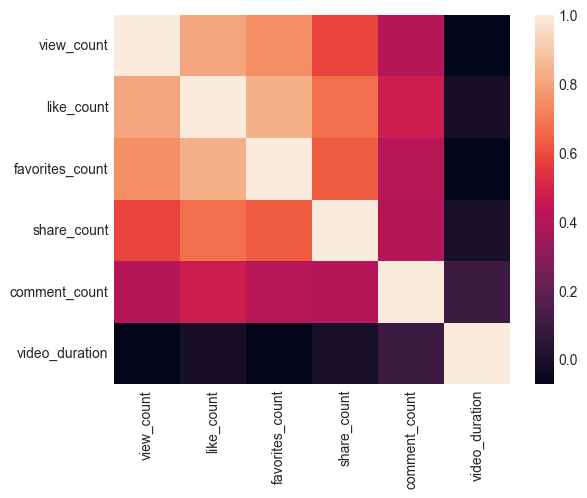

In [ ]:
# Correlation Heatmap

sns.heatmap(correlation_matrix, annot=True, cmap='Blues', fmt='.2f')


TypeError: 'Axes' object is not subscriptable